# Notebook 3: how much do we trust the labels, and what happens on a brand-new project?

**Where we are.** Notebooks 1 and 2 gave a model, honest probabilities and a re-run rule. Three questions are still open, and each matches a point from your mentor:

| Part | Question | Mentor's point |
|---|---|---|
| A | Our labels are imperfect. How much do the results depend on how we label? | label reliability |
| B | What if the project is brand new and has no history? Do a few labelled failures help? | cold start |
| C | Where does the model work and where does it fail, project by project? | generalisation |
| D | Does the model really add value over the simple job-length rule? (with error bars) | practical benefit |

Same rules as before: guess first, run, compare. Answer the **Think** boxes in your own words.

## Step 0: Setup

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss
from sklearn.model_selection import GroupKFold
from baselines import load_main, fit_predict, metrics, GROUPS

os.makedirs("results", exist_ok=True)
pd.set_option("display.width", 150)
LEAN = ["history", "run"]       # the lean model from Notebook 2
W = 1.0                         # how much the developer's waiting counts (same as Notebook 2)

def logit(p):
    p = np.clip(p, 1e-4, 1 - 1e-4); return np.log(p / (1 - p))
def sigmoid(z): return 1 / (1 + np.exp(-z))

def cv_oof(df, groups=LEAN, noise=0.0, seed=0, folds=5):
    """Predict every job with a model that never saw its project (5-fold, by project).
    If noise > 0, a share of the TRAINING labels is flipped at random; test labels stay as they are."""
    rng = np.random.default_rng(seed)
    p = np.full(len(df), np.nan)
    for tr, te in GroupKFold(folds).split(df, groups=df["repo"]):
        train = df.iloc[tr].copy()
        if noise > 0:
            flip = rng.random(len(train)) < noise
            train["y"] = np.where(flip, 1 - train["y"], train["y"])
        p[te] = fit_predict("logreg", groups, train, df.iloc[te])
    return p

def cost_of(yv, dv, rerun, X):
    f = yv == 1
    return X * (f & ~rerun).sum() + (1 + W) * dv[(~f) & rerun].sum()

def rule(p, dv, X):
    return p * X > (1 - p) * (1 + W) * dv

def saving_vs_always(yv, dv, p, X):
    return 100 * (1 - cost_of(yv, dv, rule(p, dv, X), X) / cost_of(yv, dv, np.ones(len(yv), bool), X))

data = load_main()
y = data["y"].astype(int).values
d_min = (data["job_duration_s"].fillna(data["job_duration_s"].median()) / 60).values
repos = data["repo"].values
names = list(np.unique(repos))
print(len(data), "jobs,", len(names), "projects,", f"{y.mean():.0%} flaky")

2370 jobs, 25 projects, 75% flaky


# Part A: Label reliability

## A1: What is inside the "flaky" label?

Our label comes from one fact: *the job passed when re-run*. That is a good clue but not proof. The table splits the labels into finer kinds:

- `transient_infra`: passed on re-run **and** the log mentions network/timeout/runner problems
- `transient_other`: passed on re-run, no such hint (could be a flaky test, or a fix in between)
- `metadata_pass`: a PR-title / CLA / link check that passed on re-run, probably because a person edited something, not a real flake
- `persistent`: failed again on re-run
- `ambiguous`: the re-run was cancelled, so we don't know
- `unknown`: never re-run, so we don't know

In [2]:
full = pd.read_parquet("data/dataset.parquet")
comp = full["label_detail"].value_counts().rename("jobs").to_frame()
comp["share_%"] = (100 * comp["jobs"] / comp["jobs"].sum()).round(1)
comp

,jobs,share_%
label_detail,,
transient_other,1663,51.6
unknown,733,22.7
persistent,608,18.9
transient_infra,115,3.6
metadata_pass,84,2.6
ambiguous,19,0.6


**Now a sanity check.** If our finer labels mean anything, a model that never saw these projects should give *different* average "flaky" probabilities to different kinds. Real failures should get a lower number than flaky ones.

In [3]:
p_default = cv_oof(data)
tmp = data.assign(p_flaky=p_default)
tmp.groupby("label_detail")["p_flaky"].agg(["size", "mean"]).round(3)

,size,mean
label_detail,,
persistent,592,0.679
transient_infra,115,0.814
transient_other,1663,0.753


**Think A1.** Does `persistent` get a clearly lower average than `transient_other` and `transient_infra`? If the averages are close, what does that say about how much the model can really tell the kinds apart?

*My answer:*

## A2: Does it matter how we choose and label the rows?

We rerun the same lean model under three different data choices and compare. Because the share of flaky jobs changes between scenarios, we don't compare raw scores. We compare **lift** (how many times better than random guessing at finding real failures) and **ROC-AUC** (0.5 = random).

| Scenario | What changes |
|---|---|
| **default** | what we have used so far |
| **+ metadata jobs** | put the CLA / PR-title jobs back in |
| **+ never-re-run as real** | assume the never-re-run failures were real (a developer fixed the code). This is an *assumption*, not a fact. It tests how sensitive we are to the biggest unknown in our data. |

In [4]:
def scenario_row(name, df):
    yy = df["y"].astype(int).values
    p = cv_oof(df)
    m = metrics(yy, p)
    return {"scenario": name, "jobs": len(df), "flaky_share": round(yy.mean(), 3),
            "random_PR_AUC_real": round(1 - yy.mean(), 3), "PR_AUC_real": round(m["pr_auc_real"], 3),
            "lift": round(m["pr_auc_real"] / (1 - yy.mean()), 2), "ROC_AUC": round(m["roc_auc"], 3)}

scen = pd.DataFrame([
    scenario_row("default", load_main()),
    scenario_row("+ metadata jobs", load_main(main_only=False)),
    scenario_row("+ never-re-run as real", load_main(no_rerun_as_real=True)),
])
scen

,scenario,jobs,flaky_share,random_PR_AUC_real,PR_AUC_real,lift,ROC_AUC
0,default,2370,0.750,0.250,0.379,1.52,0.652
1,+ metadata jobs,2470,0.754,0.246,0.385,1.56,0.666
2,+ never-re-run as real,3057,0.582,0.418,0.547,1.31,0.614


**How to read it.** `lift` above 1 means better than random. If the lift and ROC-AUC change a lot between rows, our conclusions depend on a labelling choice, and the report must say so. If they stay about the same, the finding is robust.

**Think A2.** Which row differs most from `default`? What would you conclude about the biggest unknown in our data, the never-re-run jobs?

*My answer:*

## A3: What if some of the labels we trust are simply wrong?

We can't know which labels are wrong, but we can *simulate* it: randomly flip a share of the **training** labels (flaky becomes real, real becomes flaky), train the model, and test it on the labels as they are. If the score barely moves as we add noise, the model is robust to label errors. If it collapses, label quality is critical.

Each noise level is repeated with 3 random seeds, so we can see the spread.

In [5]:
rows = []
for q in (0.0, 0.1, 0.2, 0.3, 0.4):
    for seed in range(3):
        p = cv_oof(data, noise=q, seed=seed)
        rows.append({"noise": q, "seed": seed, "PR_AUC_real": average_precision_score(1 - y, 1 - p),
                     "ROC_AUC": roc_auc_score(y, p)})
noise_df = pd.DataFrame(rows)
summ = noise_df.groupby("noise").agg(PR_AUC_real=("PR_AUC_real", "mean"), PR_sd=("PR_AUC_real", "std"),
                                     ROC_AUC=("ROC_AUC", "mean"), ROC_sd=("ROC_AUC", "std")).round(3)
summ

,PR_AUC_real,PR_sd,ROC_AUC,ROC_sd
noise,,,,
0.0,0.379,0.000,0.652,0.000
0.1,0.364,0.011,0.639,0.004
0.2,0.352,0.006,0.635,0.009
0.3,0.351,0.005,0.630,0.007
0.4,0.332,0.017,0.600,0.024


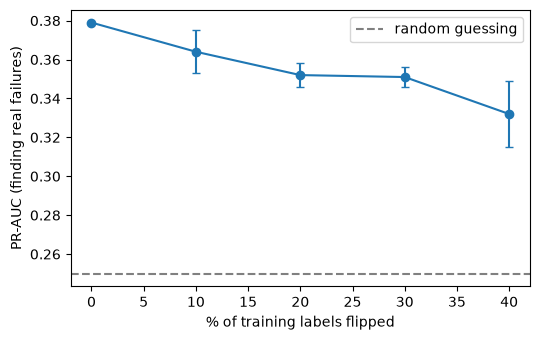

In [6]:
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.errorbar(summ.index * 100, summ["PR_AUC_real"], yerr=summ["PR_sd"], fmt="o-", capsize=3)
ax.axhline(1 - y.mean(), ls="--", c="gray", label="random guessing")
ax.set_xlabel("% of training labels flipped"); ax.set_ylabel("PR-AUC (finding real failures)")
ax.legend(); plt.tight_layout(); plt.savefig("results/label_noise.png", dpi=150)

**Think A3.** At what noise level does the score fall to random guessing? Roughly how noisy do you think the real labels are (think of the CLA bot example, jobs that pass because someone edited a title)? What does that mean for how much you trust the 0.37 from Notebook 2?

*My answer:*

# Part B: Cold start

**The problem.** The model's strongest clue is the project's *recent failure history*. A brand-new project has none. Can a handful of labelled failures from that project fix this?

**The trick (very simple).** Train on the other 24 projects. For the new project, the model gives a probability for each failure. After we see the first *k* failures *and how they turned out* (flaky or real), we check: did the model over- or under-estimate? Then we **shift all its probabilities up or down** by that amount. With few examples we shift only a little (a "prior strength" of M = 10 means the model's own opinion counts as 10 examples).

**An honest rival.** A model could simply learn "this project is usually flaky" from those k examples, without any features at all. So we also test a **rate-only** baseline: the project's observed flaky rate from the first k failures, nothing else. If the model can't beat it, the features aren't helping.

**The setup.**
- We hold each project out in turn (*leave one project out*).
- For each project, the **first 40 jobs in time order** are the "warm-up". We use only the first *k* of them to adapt.
- We **test on the jobs after the first 40**, the same jobs for every *k*, so the comparison is fair.
- Only projects with at least 60 labelled jobs are used.

In [7]:
# leave-one-project-out predictions: each project predicted by a model trained on the other 24
def lopo(groups=LEAN):
    p = np.full(len(data), np.nan); prior = np.full(len(data), np.nan)
    for r in names:
        te = np.where(repos == r)[0]; tr = np.where(repos != r)[0]
        p[te] = fit_predict("logreg", groups, data.iloc[tr], data.iloc[te])
        prior[te] = y[tr].mean()
    return p, prior

p_lopo, prior = lopo()
print("done; mean predicted flaky probability:", p_lopo.mean().round(3), " actual:", y.mean().round(3))

done; mean predicted flaky probability: 0.744  actual: 0.75


In [8]:
K_MAX, KS, M = 40, [0, 5, 10, 20, 40], 10
elig = [r for r in names if (repos == r).sum() >= K_MAX + 20]
print(len(elig), "projects have >= 60 labelled jobs and are used for the cold-start test")

store = {k: {"y": [], "d": [], "repo": [], "p_model": [], "p_rate": []} for k in KS}
for r in elig:
    idx = np.where(repos == r)[0]
    idx = idx[np.argsort(data["run_created_at"].values[idx])]
    warm, test = idx[:K_MAX], idx[K_MAX:]
    for k in KS:
        first = warm[:k]
        if k == 0:
            p_mod, p_rate = p_lopo[test], np.full(len(test), prior[test][0])
        else:
            pf = p_lopo[first].mean()
            ybar = (y[first].sum() + M * pf) / (k + M)                 # shrink towards the model's own opinion
            p_mod = sigmoid(logit(p_lopo[test]) + logit(ybar) - logit(pf))
            p_rate = np.full(len(test), (y[first].sum() + M * prior[test][0]) / (k + M))
        s = store[k]
        s["y"].append(y[test]); s["d"].append(d_min[test]); s["repo"].append(np.full(len(test), r))
        s["p_model"].append(p_mod); s["p_rate"].append(p_rate)
store = {k: {a: np.concatenate(b) for a, b in v.items()} for k, v in store.items()}
print("test jobs per setting:", len(store[0]["y"]))

18 projects have >= 60 labelled jobs and are used for the cold-start test
test jobs per setting: 1491


In [9]:
rows = []
for k in KS:
    s = store[k]
    for who in ("p_model", "p_rate"):
        p = s[who]
        rows.append({"k": k, "who": who.replace("p_", ""),
                     "brier": brier_score_loss(s["y"], p),
                     "PR_AUC_real": average_precision_score(1 - s["y"], 1 - p),
                     "saving_vs_always_X15_%": saving_vs_always(s["y"], s["d"], p, 15),
                     "saving_vs_always_X45_%": saving_vs_always(s["y"], s["d"], p, 45)})
cold = pd.DataFrame(rows).round(3)
print("random guessing PR-AUC (real):", round(1 - store[0]["y"].mean(), 3))
cold.pivot(index="k", columns="who")

random guessing PR-AUC (real): 0.239


brier        PR_AUC_real        saving_vs_always_X15_%         saving_vs_always_X45_%        
who  model   rate       model   rate                  model    rate                  model    rate
k                                                                                                 
0    0.178  0.184       0.357  0.175                 33.874  27.303                 14.787   0.661
5    0.181  0.189       0.360  0.232                 28.661  27.552                 21.573  20.640
10   0.195  0.199       0.323  0.252                 29.668  20.256                  7.288  10.697
20   0.185  0.190       0.344  0.265                 31.693  25.024                 25.501  19.478
40   0.181  0.180       0.379  0.321                 32.069  29.922                 18.513  20.239

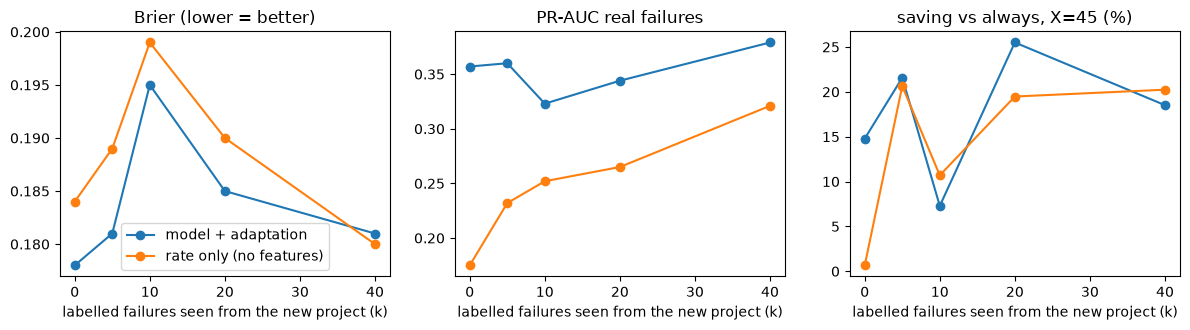

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, col, title in zip(axes, ["brier", "PR_AUC_real", "saving_vs_always_X45_%"],
                          ["Brier (lower = better)", "PR-AUC real failures", "saving vs always, X=45 (%)"]):
    for who, lab in (("model", "model + adaptation"), ("rate", "rate only (no features)")):
        s = cold[cold.who == who]; ax.plot(s["k"], s[col], "o-", label=lab)
    ax.set_xlabel("labelled failures seen from the new project (k)"); ax.set_title(title)
axes[0].legend(); plt.tight_layout(); plt.savefig("results/cold_start.png", dpi=150)

**How to read it.** `k = 0` is the pure cold start (no adaptation). Moving right shows what a few labelled failures buy us. The key comparison at every k is **model vs rate-only**: if they are about equal, the features add nothing and "know your project's flaky rate" is all that matters.

**Think B.** (a) How many labelled failures does it take before things improve noticeably? (b) Does the model beat the rate-only baseline, or are they about the same? (c) What would you tell a team that adopts this tool on a new project?

*My answer:*

### Are the cold-start differences real? (error bars)

Same idea as Notebook 2: redraw the projects with replacement 500 times and look at the spread. Here we ask three questions at k = 20.

In [11]:
rng = np.random.default_rng(0)
B, KB, XB = 500, 20, 45
sk0, skb = store[0], store[KB]
by_proj = {r: np.where(sk0["repo"] == r)[0] for r in elig}   # same test rows for every k, same order

def ci(a): return f"{np.mean(a):+.3f}  [{np.percentile(a, 2.5):+.3f}, {np.percentile(a, 97.5):+.3f}]"
out = {"brier_k20_minus_k0 (model)": [], "PR_AUC_model_minus_rate (k=20)": [],
       f"saving_X{XB}_model_minus_rate (k=20)": []}
for _ in range(B):
    idx = np.concatenate([by_proj[r] for r in rng.choice(elig, len(elig), replace=True)])
    yb, db = skb["y"][idx], skb["d"][idx]
    out["brier_k20_minus_k0 (model)"].append(brier_score_loss(yb, skb["p_model"][idx]) - brier_score_loss(yb, sk0["p_model"][idx]))
    out["PR_AUC_model_minus_rate (k=20)"].append(average_precision_score(1 - yb, 1 - skb["p_model"][idx]) - average_precision_score(1 - yb, 1 - skb["p_rate"][idx]))
    out[f"saving_X{XB}_model_minus_rate (k=20)"].append(saving_vs_always(yb, db, skb["p_model"][idx], XB) - saving_vs_always(yb, db, skb["p_rate"][idx], XB))
for k_, v in out.items():
    print(f"{k_:<40}", ci(v))
print("\n(for Brier, NEGATIVE means adaptation helped; for the other two, POSITIVE means the model beats rate-only)")
print("(an interval that contains 0 means: not proven)")

brier_k20_minus_k0 (model)               +0.007  [-0.014, +0.029]
PR_AUC_model_minus_rate (k=20)           +0.072  [+0.010, +0.131]
saving_X45_model_minus_rate (k=20)       +6.415  [+1.793, +13.443]

(for Brier, NEGATIVE means adaptation helped; for the other two, POSITIVE means the model beats rate-only)
(an interval that contains 0 means: not proven)


**Think B2.** Based on these intervals, state in two sentences what you can and cannot claim about cold start.

*My answer:*

# Part C: Where does it work and where does it fail?

One pooled score hides a lot. Here is the result **per project** for the lean model on projects it has never seen (the leave-one-project-out predictions). A score is only shown when a project has at least 5 flaky and 5 real jobs, otherwise it would be meaningless.

In [12]:
rows = []
for r in names:
    m = repos == r
    yy, pp, dd = y[m], p_lopo[m], d_min[m]
    ok = (yy == 1).sum() >= 5 and (yy == 0).sum() >= 5
    rows.append({"project": r, "jobs": int(m.sum()), "flaky_share": round(yy.mean(), 2),
                 "PR_AUC_real": round(average_precision_score(1 - yy, 1 - pp), 3) if ok else np.nan,
                 "random_guess": round(1 - yy.mean(), 3),
                 "ROC_AUC": round(roc_auc_score(yy, pp), 3) if ok else np.nan,
                 "saving_vs_always_X15_%": round(saving_vs_always(yy, dd, pp, 15), 1)})
per = pd.DataFrame(rows).sort_values("jobs", ascending=False).reset_index(drop=True)
per.to_csv("results/per_project.csv", index=False)
per

,project,jobs,flaky_share,PR_AUC_real,random_guess,ROC_AUC,saving_vs_always_X15_%
0,vercel/next.js,303,0.69,0.371,0.310,0.621,28.4
1,PrestaShop/PrestaShop,208,0.91,0.183,0.087,0.634,-82.5
2,hashicorp/consul,192,0.80,0.267,0.198,0.435,11.0
3,RocketChat/Rocket.Chat,171,0.76,0.316,0.240,0.561,-5.0
4,woocommerce/woocommerce,164,0.78,0.295,0.220,0.556,0.0
5,juspay/hyperswitch,140,0.67,0.397,0.329,0.557,28.1
6,paperclipai/paperclip,123,0.90,0.142,0.098,0.612,0.0
7,strapi/strapi,103,0.71,0.546,0.291,0.766,-26.7
8,prometheus/prometheus,97,0.77,0.284,0.227,0.589,-7.4
9,netty/netty,96,0.72,0.502,0.281,0.561,30.7


In [13]:
sub = per.dropna(subset=["ROC_AUC"])
print(f"{len(sub)} projects have both classes with >=5 jobs")
print(f"projects where ROC-AUC > 0.5 : {(sub.ROC_AUC > 0.5).sum()}  of {len(sub)}")
print(f"projects where PR-AUC beats random guessing: {(sub.PR_AUC_real > sub.random_guess).sum()}  of {len(sub)}")
print(f"projects where the rule saves money vs 'always' (X=15): {(per['saving_vs_always_X15_%'] > 0).sum()}  of {len(per)}")

20 projects have both classes with >=5 jobs
projects where ROC-AUC > 0.5 : 16  of 20
projects where PR-AUC beats random guessing: 19  of 20
projects where the rule saves money vs 'always' (X=15): 10  of 25


**Think C.** Is the model good on most projects, or is the pooled result carried by a few? Name one project where it fails clearly. Can you think of a *reason* (type of project, kind of jobs, share of flaky failures) why it fails there? Look at the project's `flaky_share` before answering.

*My answer:*

# Part D: Does the model add value beyond job length? (with error bars across X)

In Notebook 2 the duration-only rule captured most of the saving at X = 15, and the model's extra had an interval that included 0. The extra looked larger at X = 45 but had no error bar. Here we compute it for several X, using the leave-one-project-out predictions, with a bootstrap over projects.

In [14]:
rng = np.random.default_rng(1)
by_repo = {r: np.where(repos == r)[0] for r in names}
XS = [2, 5, 15, 45]
res = {X: [] for X in XS}
def saving_vs_dur(idx, X):
    cm = cost_of(y[idx], d_min[idx], rule(p_lopo[idx], d_min[idx], X), X)
    cd = cost_of(y[idx], d_min[idx], rule(prior[idx], d_min[idx], X), X)
    return 100 * (1 - cm / cd)
for _ in range(500):
    idx = np.concatenate([by_repo[r] for r in rng.choice(names, len(names), replace=True)])
    for X in XS: res[X].append(saving_vs_dur(idx, X))
allidx = np.arange(len(y))
rows = [{"X": X, "model_extra_saving_%": round(saving_vs_dur(allidx, X), 1),
         "95%_low": round(np.percentile(res[X], 2.5), 1), "95%_high": round(np.percentile(res[X], 97.5), 1),
         "proven (interval above 0)": np.percentile(res[X], 2.5) > 0} for X in XS]
extra = pd.DataFrame(rows); extra.to_csv("results/model_extra_value.csv", index=False); extra

,X,model_extra_saving_%,95%_low,95%_high,proven (interval above 0)
0,2,5.3,-9.4,19.4,False
1,5,-0.5,-14.5,9.1,False
2,15,2.2,-16.6,16.3,False
3,45,13.6,-17.2,42.7,False


**Think D.** For which X (if any) is the model's extra saving *proven* (the interval is entirely above 0)? What does that tell you about when it is worth running the model instead of the simple job-length rule?

*My answer:*

# Your conclusions for Notebook 3

Write 6 to 10 sentences in your own words. Cover: (1) how sensitive the results are to how we label; (2) what cold start tells you about deploying on a new project; (3) where the model fails; (4) when the model is worth running compared with the simple rule. These are the points an examiner will push on.

*My conclusions:*